# Solutions

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Polynomial fitting with SVD

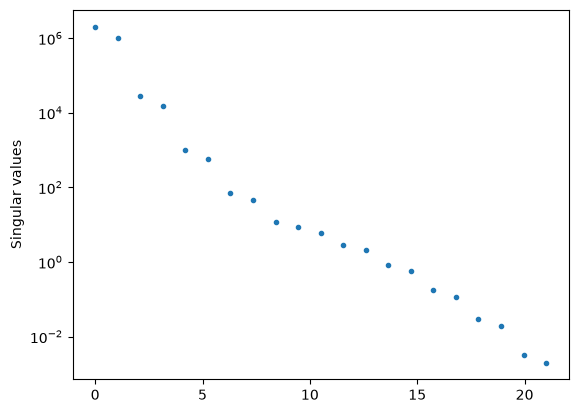

Range of singular values = 1.02088e+09
np.linalg.cond gives 1.02088e+09
Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0      0.571233      0.571233   2.25452e-13
x^1      -0.19439      -0.19439  -4.36115e-10
x^2      0.807578      0.807578   1.05668e-10
x^3      0.304404      0.304404  -7.10668e-09
x^4      0.270141      0.270141  -4.76118e-09
x^5     -0.846047     -0.846047  -1.07527e-08
x^6     -0.220974     -0.220974  -4.04902e-09
x^7      0.743566      0.743566  -2.42204e-08
x^8      0.939299      0.939299   4.09705e-09
x^9      -0.96933      -0.96933  -2.28183e-08
x^10     -0.188162     -0.188162  -8.51519e-08
x^11     -0.470765     -0.470765   1.96634e-08
x^12     -0.464371     -0.464371   8.28745e-09
x^13      0.226164      0.226164   2.12962e-08
x^14     -0.985914     -0.985914  -4.20537e-09
x^15      0.203236      0.203236  -3.33501e-09
x^16      0.739975      0.739975   4.93283e-10
x^17     -0.608647     -0.608647  -4.40087e-10
x^18     0.0981553     

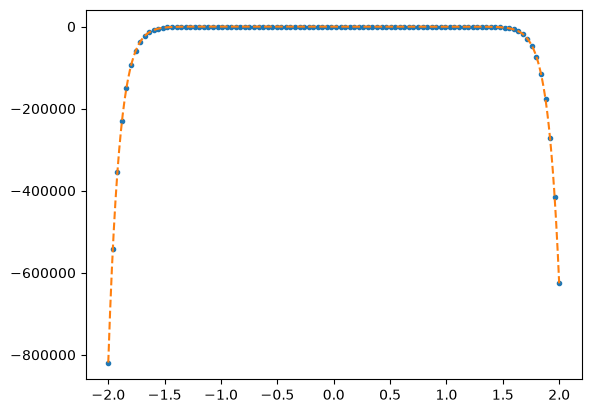

In [15]:
# first generate some data from a random polynomial

k = 20 # order of polynomial
n = 100  # number of data points
sigma = 0 # noise
useSVD = True

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk
# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

# plot the singular values
plt.clf()
plt.plot(np.linspace(0,len(Sdiag),len(Sdiag)),Sdiag,'.')
plt.yscale('log')
plt.ylabel(r'Singular values')
plt.show()
    
print("Range of singular values = %g" % (max(abs(Sdiag))/min(abs(Sdiag))))
print("np.linalg.cond gives %g" % (np.linalg.cond(A)))

# Now do the linear algebra part
if useSVD:
    a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
else:
    rhs = np.transpose(A)@y
    lhs = np.transpose(A)@A
    a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
plt.figure()
plt.plot(x,y,'.')
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()

## Orthogonal polynomials

In [84]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

In [85]:
# first generate some data from a random polynomial
k = 20  # order of polynomial
n = 100   # number of data points

kfit = 20  # number of basis functions for the fit

x = np.linspace(-2,2,n)
a0 = -1.0 + 2*np.random.rand(k+1)
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=0.0, size=n)

# OR try a more complicated function
#y = np.exp(np.sin(x**3)) + np.tanh(x)**3

In [86]:
def do_fit(A, y, use_svd = True):
    
    if use_svd:
        U, Sdiag, VT = np.linalg.svd(A,0)
        a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
    else:
        rhs = np.transpose(A)@y
        lhs = np.transpose(A)@A
        a = np.linalg.inv(lhs)@rhs

    return a

<Figure size 640x480 with 0 Axes>

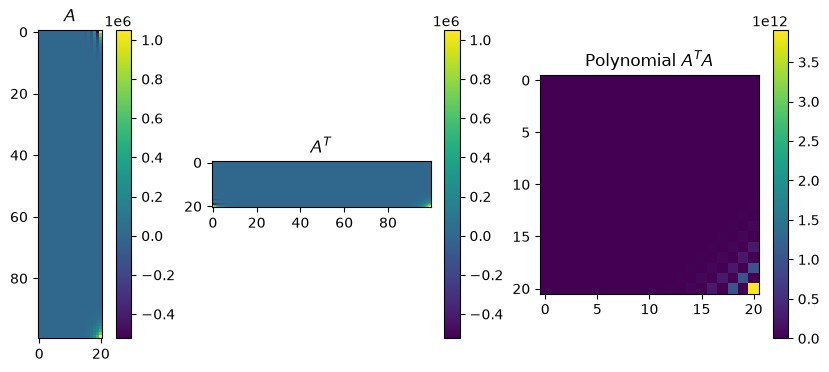

<Figure size 640x480 with 0 Axes>

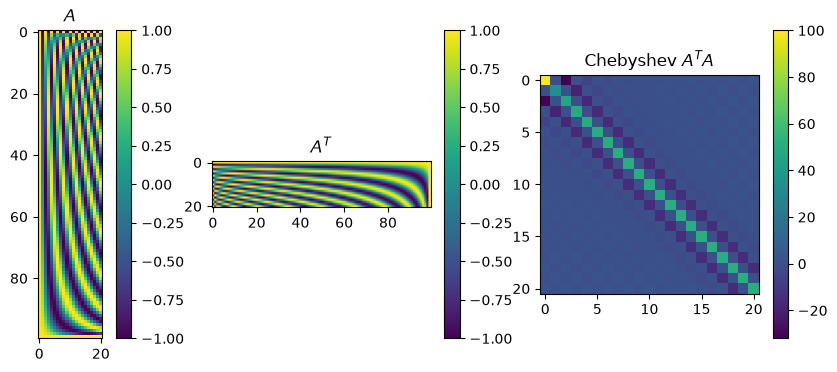

Condition number = 3.1319
Chebyshev coefficients:
a0 171665
a1 213568
a2 311503
a3 173924
a4 232228
a5 114892
a6 141429
a7 61037.5
a8 69633
a9 25702.5
a10 27268.9
a11 8383.15
a12 8286.48
a13 2041.7
a14 1881.14
a15 349.263
a16 299.792
a17 37.3919
a18 29.8782
a19 1.88156
a20 1.39951
mean square deviation = 1.19342e-19


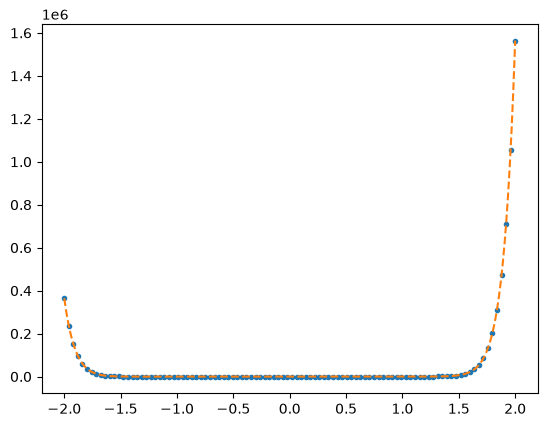

In [87]:
A = np.vander(x, N=kfit+1, increasing=True)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Polynomial $A^TA$"])

# Fit with Chebyshev polynomials
A = np.polynomial.chebyshev.chebvander(x/2,kfit)

plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Chebyshev $A^TA$"])

print("Condition number = %g" % (np.linalg.cond(A)))

a_cheb = do_fit(A, y)
      
print("Chebyshev coefficients:")
for i in range(len(a_cheb)):
    print("a%d %g" % (i, a_cheb[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_cheb = np.polynomial.Chebyshev(a_cheb)
yy = poly_cheb(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_cheb(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

Condition number = 6.42377


<Figure size 640x480 with 0 Axes>

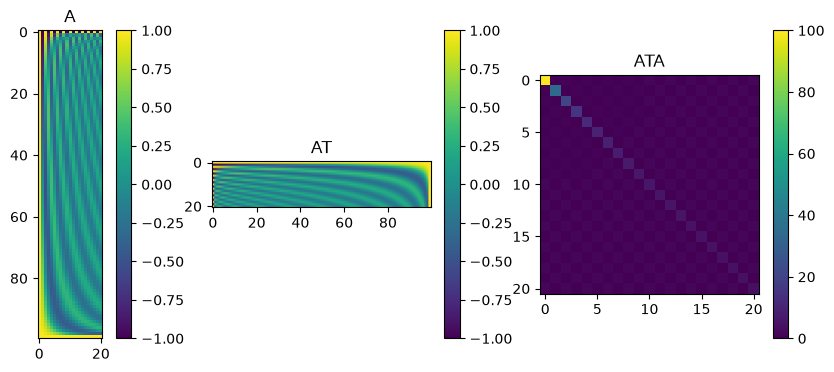

Legendre coefficients:
a0 46857.7
a1 87472.3
a2 203153
a3 158786
a4 261519
a5 158034
a6 221385
a7 110113
a8 137530
a9 56642.6
a10 64336.8
a11 21619.5
a12 22549.9
a13 5987.74
a14 5762.51
a15 1141.3
a16 1015.52
a17 134.082
a18 110.406
a19 7.31638
a20 5.58147
mean square deviation = 2.4721e-18


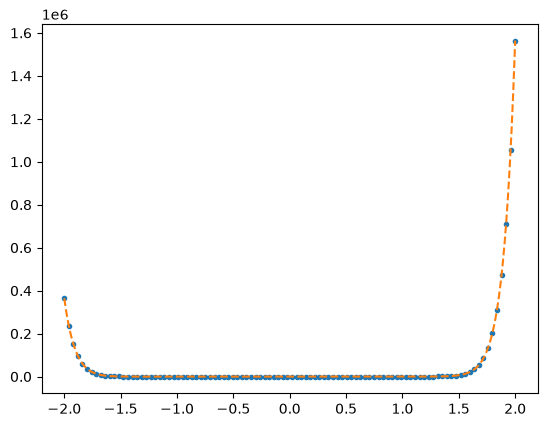

In [88]:
# Fit with Legendre polynomials
A = np.polynomial.legendre.legvander(x/2,kfit)

print("Condition number = %g" % (np.linalg.cond(A)))
plot_matrices([A,A.T,A.T@A], titles=["A","AT","ATA"])

a_leg = do_fit(A, y)
      
print("Legendre coefficients:")
for i in range(len(a_leg)):
    print("a%d %g" % (i, a_leg[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_leg = np.polynomial.Legendre(a_leg)
yy = poly_leg(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_leg(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()